In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Input

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
print(df.head())


Saving World_Energy_By_Country_And_Region_1965_to_2023.csv to World_Energy_By_Country_And_Region_1965_to_2023 (1).csv
Dataset shape: (111, 60)
Columns: ['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
               Country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54

In [ ]:

print(df.columns.tolist())
print(df.head(3))


['Country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
  Country  1965  1966  1967  1968  1969  1970  1971  1972  1973  ...   2014  \
0     NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN   NaN  ...    NaN   
1  Canada  5.00  5.32  5.57  5.92  6.28  6.73  6.94  7.47  8.11  ...  14.43   
2  Mexico  1.06  1.12  1.14  1.24  1.36  1.45  1.53  1.69  1.82  ...   8.03   

    2015   2016   2017   2018   2019   2020   2021   2022   2023  
0    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN  
1  14.47  14.34  14.54  14.72  14.64  13.76  13.92  14.30  13.95 

In [ ]:

# Clean column names
df.columns = df.columns.str.strip().str.lower()

print("Available columns:")
print(df.columns.tolist())


Available columns:
['country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']


In [ ]:

import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

# Convert wide format to long format
year_columns = [
    col for col in df.columns
    if col.isdigit()
]

data = df.melt(
    id_vars=['country'],
    value_vars=year_columns,
    var_name='year',
    value_name='primary_energy_consumption'
)

# Clean the data
data['year'] = pd.to_numeric(data['year'], errors='coerce')
data['primary_energy_consumption'] = pd.to_numeric(
    data['primary_energy_consumption'], errors='coerce'
)

data = data.dropna(
    subset=['country', 'year', 'primary_energy_consumption']
)

# Select India
country = data[data['country'] == 'India'].copy()
country = country.sort_values('year')
country = country.drop_duplicates(subset='year')

# Check output
print(country.head())
print("Total records:", len(country))
print("Year range:", country['year'].min(), "to",
      country['year'].max())


    country  year  primary_energy_consumption
91    India  1965                        2.23
202   India  1966                        2.30
313   India  1967                        2.37
424   India  1968                        2.53
535   India  1969                        2.81
Total records: 59
Year range: 1965 to 2023


In [ ]:

values = country['primary_energy_consumption'].values.reshape(-1, 1)
years = country['year'].values

split = int(len(values) * 0.8)

scaler = MinMaxScaler()
scaler.fit(values[:split])
scaled = scaler.transform(values)

X, y, target_years = [], [], []

for i in range(5, len(scaled)):
    X.append(scaled[i-5:i])
    y.append(scaled[i, 0])
    target_years.append(years[i])

X = np.array(X)
y = np.array(y)
target_years = np.array(target_years)

train_mask = target_years < years[split]
test_mask = ~train_mask

X_train, y_train = X[train_mask], y[train_mask]
X_test, y_test = X[test_mask], y[test_mask]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)


Training shape: (42, 5, 1)
Testing shape: (12, 5, 1)


In [ ]:

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense

tf.random.set_seed(42)

model = Sequential([
    Input(shape=(5, 1)),
    LSTM(32),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mse'
)

model.summary()

history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=8,
    shuffle=False,
    verbose=1
)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_1 (LSTM)                   │ (None, 32)             │         4,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,385 (17.13 KB)

 Trainable params: 4,385 (17.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - loss: 0.2097
Epoch 2/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1659     
Epoch 3/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.1293     
Epoch 4/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0984 
Epoch 5/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0730
Epoch 6/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0528 
Epoch 7/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0379 
Epoch 8/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0285 
Epoch 9/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0240 
Epoch 10/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0231 
Epoch 11/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0238 
Epoch 12/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0241 
Epoch 13/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0232 
Epoch 14/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0211 
Epoch 15/50
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0185 
Epoch 16/50
6/6 ━━━━━━━━━━━

MAE: 3.1339
RMSE: 3.551


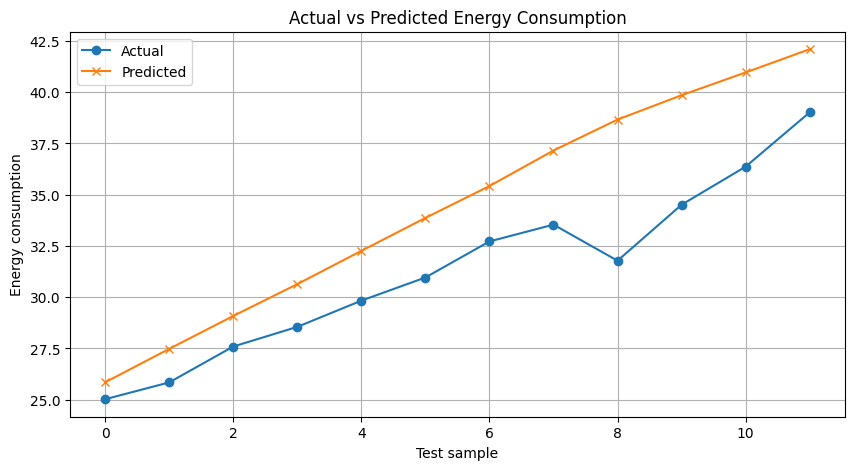

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

pred_scaled = model.predict(X_test, verbose=0)

y_actual = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

y_pred = scaler.inverse_transform(
    pred_scaled
).flatten()

mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))

plt.figure(figsize=(10, 5))
plt.plot(y_actual, marker='o', label='Actual')
plt.plot(y_pred, marker='x', label='Predicted')
plt.xlabel('Test sample')
plt.ylabel('Energy consumption')
plt.title('Actual vs Predicted Energy Consumption')
plt.legend()
plt.grid(True)
plt.show()


    Year  Actual  Predicted
0   2012   25.02  25.843784
1   2013   25.84  27.477182
2   2014   27.59  29.082691
3   2015   28.55  30.636005
4   2016   29.83  32.259270
5   2017   30.96  33.867344
6   2018   32.72  35.422573
7   2019   33.54  37.156887
8   2020   31.78  38.666752
9   2021   34.51  39.855972
10  2022   36.37  40.967438
11  2023   39.02  42.100571


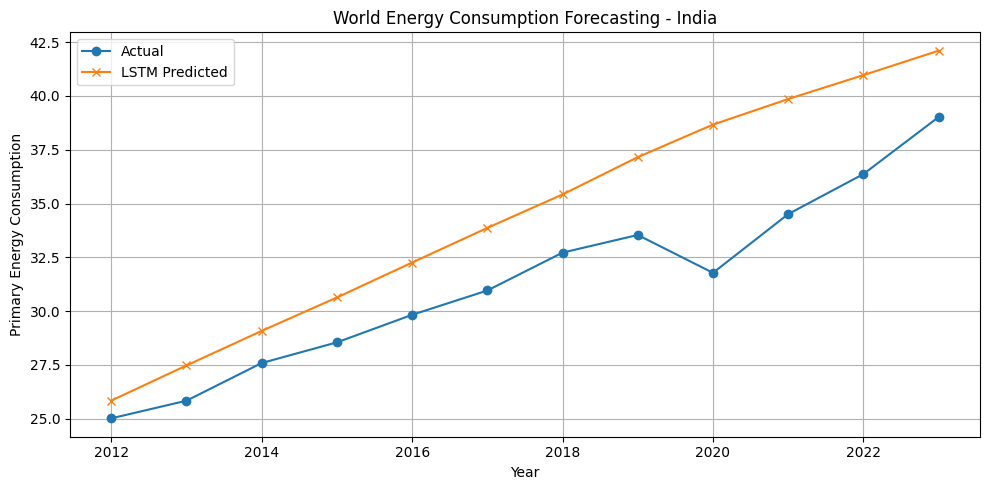

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

# Create results table using existing variables
results = pd.DataFrame({
    'Year': target_years[test_mask],
    'Actual': y_actual,
    'Predicted': y_pred
})

print(results)

# Plot graph
plt.figure(figsize=(10, 5))

plt.plot(
    results['Year'], results['Actual'],
    marker='o', label='Actual'
)

plt.plot(
    results['Year'], results['Predicted'],
    marker='x', label='LSTM Predicted'
)

plt.title('World Energy Consumption Forecasting - India')
plt.xlabel('Year')
plt.ylabel('Primary Energy Consumption')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('energy_forecasting.png', dpi=300)
plt.show()


In [ ]:

from google.colab import files
files.download('energy_forecasting.png')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# 1. Inspect the original dataset
print("Original shape:", df.shape)
print("Original columns:", df.columns.tolist())
print(df.head())

# 2. Convert wide format into long format
year_columns = [col for col in df.columns if col.isdigit()]

data = df.melt(
    id_vars=['country'],
    value_vars=year_columns,
    var_name='year',
    value_name='primary_energy_consumption'
)

# 3. Convert to numeric data types
data['year'] = pd.to_numeric(data['year'], errors='coerce')
data['primary_energy_consumption'] = pd.to_numeric(
    data['primary_energy_consumption'], errors='coerce'
)

# 4. Inspect missing values
print("Missing values before cleaning:")
print(data[['year', 'primary_energy_consumption']].isna().sum())

# 5. Remove rows missing required values
data = data.dropna(
    subset=['country', 'year', 'primary_energy_consumption']
)

# 6. Select India and sort chronologically
country = data[data['country'] == 'India'].copy()
country = country.sort_values('year')
country = country.drop_duplicates(subset='year')

print("Cleaned records:", len(country))
print("Year range:", country['year'].min(), "-", country['year'].max())
print(country.head())


Original shape: (111, 60)
Original columns: ['country', '1965', '1966', '1967', '1968', '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977', '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016', '2017', '2018', '2019', '2020', '2021', '2022', '2023']
               country   1965   1966   1967   1968   1969   1970   1971  \
0                  NaN    NaN    NaN    NaN    NaN    NaN    NaN    NaN   
1               Canada   5.00   5.32   5.57   5.92   6.28   6.73   6.94   
2               Mexico   1.06   1.12   1.14   1.24   1.36   1.45   1.53   
3                   US  51.98  54.89  56.80  60.19  63.30  65.54  66.92   
4  Total North America  58.04  61.33  63.51  67.36  70.95  73.72  75.39   

    1972   1973  ... 

In [ ]:

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

# Actual and predicted values are already in original units
mae = mean_absolute_error(y_actual, y_pred)
rmse = np.sqrt(mean_squared_error(y_actual, y_pred))
r2 = r2_score(y_actual, y_pred)

# MAPE: exclude zero actual values
nonzero = y_actual != 0

if np.any(nonzero):
    mape = np.mean(
        np.abs(
            (y_actual[nonzero] - y_pred[nonzero])
            / y_actual[nonzero]
        )
    ) * 100
else:
    mape = np.nan

print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))
print("MAPE (%):", round(mape, 2))


MAE: 3.1339
RMSE: 3.551
R2 Score: 0.2269
MAPE (%): 9.72


In [ ]:

import pandas as pd
import numpy as np

comparison = pd.DataFrame({
    "Year": target_years[test_mask],
    "Actual": y_actual,
    "Predicted": y_pred
})

comparison["Absolute_Error"] = abs(
    comparison["Actual"] - comparison["Predicted"]
)

comparison["Error_Percentage"] = (
    comparison["Absolute_Error"]
    / comparison["Actual"].abs().replace(0, np.nan)
) * 100

print(comparison.round(3).to_string(index=False))


 Year  Actual  Predicted  Absolute_Error  Error_Percentage
 2012   25.02  25.844000           0.824             3.293
 2013   25.84  27.476999           1.637             6.336
 2014   27.59  29.083000           1.493             5.410
 2015   28.55  30.636000           2.086             7.306
 2016   29.83  32.258999           2.429             8.144
 2017   30.96  33.867001           2.907             9.391
 2018   32.72  35.423000           2.703             8.260
 2019   33.54  37.157001           3.617            10.784
 2020   31.78  38.667000           6.887            21.670
 2021   34.51  39.855999           5.346            15.491
 2022   36.37  40.966999           4.597            12.641
 2023   39.02  42.101002           3.081             7.895


In [ ]:

import numpy as np
import pandas as pd

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Model 1: Previous year's value as prediction (baseline)
baseline_scaled = X_test[:, -1, 0].reshape(-1, 1)
baseline_pred = scaler.inverse_transform(baseline_scaled).flatten()

# Model 2: Linear Regression using previous 5 years
lr = LinearRegression()
lr.fit(X_train.reshape(len(X_train), -1), y_train)

lr_scaled = lr.predict(X_test.reshape(len(X_test), -1))
lr_pred = scaler.inverse_transform(
    lr_scaled.reshape(-1, 1)
).flatten()

# Compare all three models on the same test years
def evaluate(name, actual, predicted):
    mape = np.mean(
        np.abs((actual - predicted) / np.maximum(np.abs(actual), 1e-8))
    ) * 100

    return {
        "Model": name,
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "R2": r2_score(actual, predicted),
        "MAPE (%)": mape,
        "Approx. MAPE-based accuracy (%)": 100 - mape
    }

results_comparison = pd.DataFrame([
    evaluate("Previous-year baseline", y_actual, baseline_pred),
    evaluate("Linear Regression", y_actual, lr_pred),
    evaluate("LSTM", y_actual, y_pred)
])

print(results_comparison.round(3).to_string(index=False))


                 Model   MAE  RMSE    R2  MAPE (%)  Approx. MAPE-based accuracy (%)
Previous-year baseline 1.568 1.684 0.826     4.929                           95.071
     Linear Regression 0.777 1.226 0.908     2.437                           97.563
                  LSTM 3.134 3.551 0.227     9.718                           90.282


FINAL LINEAR REGRESSION RESULTS
--------------------------------
MAE: 0.7766
RMSE: 1.2257
R2 Score: 0.9079
MAPE: 2.44%
Approximate MAPE-based accuracy: 97.56%

Actual vs Predicted:
    Actual  Predicted
0    25.02     24.925
1    25.84     26.328
2    27.59     27.282
3    28.55     28.961
4    29.83     30.225
5    30.96     31.389
6    32.72     32.513
7    33.54     34.503
8    31.78     35.443
9    34.51     33.146
10   36.37     35.405
11   39.02     39.052


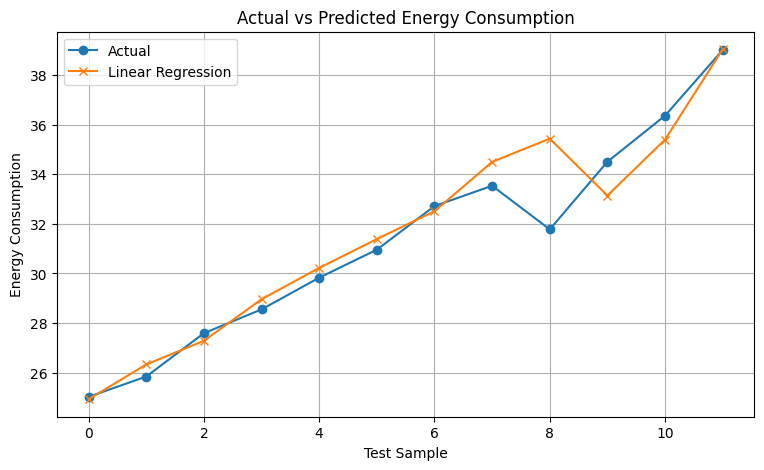

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Predict using Linear Regression
lr_scaled = lr.predict(X_test.reshape(len(X_test), -1))

lr_pred = scaler.inverse_transform(
    lr_scaled.reshape(-1, 1)
).flatten()

# Calculate metrics
mae = mean_absolute_error(y_actual, lr_pred)
rmse = np.sqrt(mean_squared_error(y_actual, lr_pred))
r2 = r2_score(y_actual, lr_pred)

nonzero = y_actual != 0
mape = np.mean(
    np.abs((y_actual[nonzero] - lr_pred[nonzero])
           / y_actual[nonzero])
) * 100

approx_accuracy = 100 - mape

print("FINAL LINEAR REGRESSION RESULTS")
print("--------------------------------")
print(f"MAE: {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R2 Score: {r2:.4f}")
print(f"MAPE: {mape:.2f}%")
print(f"Approximate MAPE-based accuracy: {approx_accuracy:.2f}%")

# Actual vs predicted comparison
comparison = pd.DataFrame({
    "Actual": y_actual,
    "Predicted": lr_pred
})
print("\nActual vs Predicted:")
print(comparison.round(3))

plt.figure(figsize=(9, 5))
plt.plot(y_actual, marker='o', label='Actual')
plt.plot(lr_pred, marker='x', label='Linear Regression')
plt.title('Actual vs Predicted Energy Consumption')
plt.xlabel('Test Sample')
plt.ylabel('Energy Consumption')
plt.legend()
plt.grid(True)
plt.show()


LSTM - INDIA ENERGY CONSUMPTION FORECAST
 Year  Predicted Energy Consumption
 2024                     42.997002
 2025                     44.459000
 2026                     47.012001
 2027                     49.314999
 2028                     51.587002
 2029                     53.605000
 2030                     55.063999
 2031                     56.523998
 2032                     57.743999
 2033                     58.763000


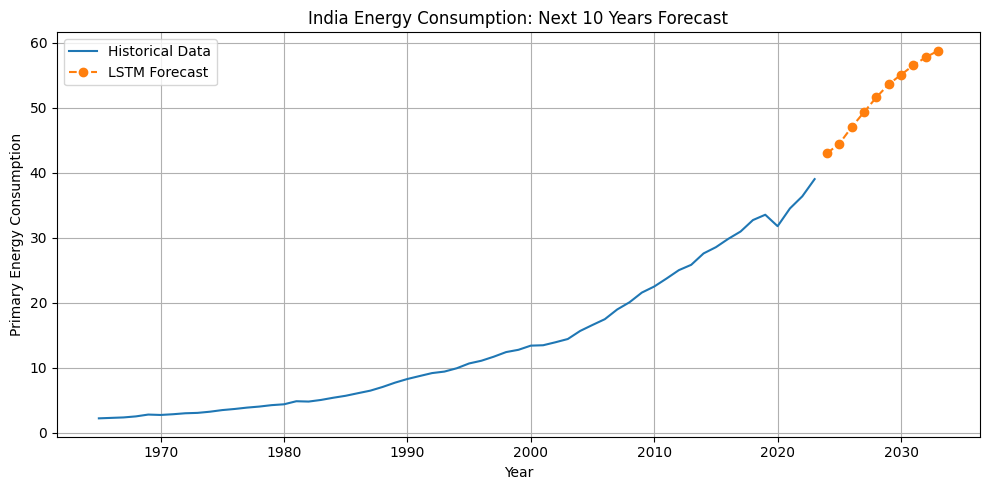

In [22]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Start with the last 5 known yearly values
last_sequence = scaled[-5:].copy()

future_years = []
future_predictions = []

# Predict the next 10 years recursively
for year in range(2024, 2034):
    # LSTM expects shape: (samples, timesteps, features)
    X_future = last_sequence.reshape(1, 5, 1)

    # Predict the next year's scaled energy consumption
    next_scaled = model.predict(X_future, verbose=0)[0, 0]

    # Convert prediction back to original scale
    next_value = scaler.inverse_transform(
        np.array([[next_scaled]])
    )[0, 0]

    future_years.append(year)
    future_predictions.append(next_value)

    # Add the prediction to the sequence for the next forecast
    last_sequence = np.vstack([
        last_sequence[1:],
        [[next_scaled]]
    ])

# Display forecast
forecast_df = pd.DataFrame({
    "Year": future_years,
    "Predicted Energy Consumption": future_predictions
})

print("LSTM - INDIA ENERGY CONSUMPTION FORECAST")
print(forecast_df.round(3).to_string(index=False))

# Plot forecast
plt.figure(figsize=(10, 5))
plt.plot(years, country["primary_energy_consumption"].values,
         label="Historical Data")
plt.plot(future_years, future_predictions,
         marker="o", linestyle="--", label="LSTM Forecast")

plt.title("India Energy Consumption: Next 10 Years Forecast")
plt.xlabel("Year")
plt.ylabel("Primary Energy Consumption")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
